# Instance Segmentation: Panoptic Indoor v5
**Variabel NRP (digit terakhir 1): ukuran input 320 / 640 / 960**

| Model | Keluarga | Ukuran input |
|---|---|---|
| YOLO11s-seg | one-stage, CNN | 320, 640, 960 |
| YOLOv8s-seg | one-stage, CNN | 640 |
| Mask R-CNN (R50-FPN v2) | two-stage, CNN | 640 |

In [7]:
# ===== KONFIGURASI =====
SMOKE_TEST  = False
SIZES       = [320, 640, 960]
BASE_SIZE   = 640
EPOCHS      = 50
TIME_HOURS  = 1.8
PRETRAINED  = True
SEED        = 42
RUN_MASKRCNN_ALL_SIZES = False

BATCH_YOLO = {320: 32, 640: 16, 960: 8}
BATCH_RCNN = {320: 8,  640: 4,  960: 2}

if SMOKE_TEST:
    EPOCHS, TIME_HOURS = 1, 0.05

In [8]:
!pip -q install roboflow ultralytics pycocotools

import os, json, time, shutil, csv, random
import numpy as np
from pathlib import Path
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

SAVE_DIR = "/kaggle/working/saved_runs" + ("_smoke" if SMOKE_TEST else "")
os.makedirs(SAVE_DIR, exist_ok=True)

RES_PATH = f"{SAVE_DIR}/results_summary.json"
RESULTS = json.load(open(RES_PATH)) if os.path.exists(RES_PATH) else {}
def log_result(key, **kw):
    RESULTS.setdefault(key, {}).update(kw)
    json.dump(RESULTS, open(RES_PATH, "w"), indent=1)

import torch
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
cfg = dict(SMOKE_TEST=SMOKE_TEST, SIZES=SIZES, BASE_SIZE=BASE_SIZE, EPOCHS=EPOCHS, TIME_HOURS=TIME_HOURS,
           PRETRAINED=PRETRAINED, SEED=SEED, BATCH_YOLO=BATCH_YOLO, BATCH_RCNN=BATCH_RCNN, GPU=gpu)
json.dump(cfg, open(f"{SAVE_DIR}/config.json", "w"), indent=1)
print("GPU:", gpu); print(cfg)

rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))
project = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation")
version = project.version(5)
version.download("coco-segmentation", location="/kaggle/working/dataset_coco")

GPU: Tesla T4
{'SMOKE_TEST': False, 'SIZES': [320, 640, 960], 'BASE_SIZE': 640, 'EPOCHS': 50, 'TIME_HOURS': 1.8, 'PRETRAINED': True, 'SEED': 42, 'BATCH_YOLO': {320: 32, 640: 16, 960: 8}, 'BATCH_RCNN': {320: 8, 640: 4, 960: 2}, 'GPU': 'Tesla T4'}
loading Roboflow workspace...
loading Roboflow project...


## Data: cek dan konversi COCO -> format YOLO-seg

In [9]:
ROOT = "/kaggle/working/dataset_coco"
coco = json.load(open(f"{ROOT}/train/_annotations.coco.json"))
print(len(coco["images"]), "gambar train,", len(coco["annotations"]), "anotasi")
print("Contoh polygon:", str(coco["annotations"][0]["segmentation"])[:100])

used = sorted({a["category_id"] for a in coco["annotations"]})
cats = {c["id"]: c["name"] for c in coco["categories"]}
NAMES = [cats[c] for c in used]
name2idx = {n: i for i, n in enumerate(NAMES)}
print(len(NAMES), "kelas aktif")

def coco_to_yolo_seg(src, dst):
    src, dst = Path(src), Path(dst)
    d = json.load(open(src / "_annotations.coco.json"))
    cid2idx = {c["id"]: name2idx[c["name"]] for c in d["categories"] if c["name"] in name2idx}
    (dst / "images").mkdir(parents=True, exist_ok=True)
    (dst / "labels").mkdir(parents=True, exist_ok=True)
    imgs = {im["id"]: im for im in d["images"]}
    lines = {i: [] for i in imgs}
    for a in d["annotations"]:
        if a["category_id"] not in cid2idx or not isinstance(a["segmentation"], list):
            continue
        im = imgs[a["image_id"]]; w, h = im["width"], im["height"]
        for seg in a["segmentation"]:
            if len(seg) < 6:
                continue
            pts = [f"{seg[i]/w:.6f} {seg[i+1]/h:.6f}" for i in range(0, len(seg), 2)]
            lines[a["image_id"]].append(f"{cid2idx[a['category_id']]} " + " ".join(pts))
    for iid, im in imgs.items():
        shutil.copy(src / im["file_name"], dst / "images" / im["file_name"])
        (dst / "labels" / (Path(im["file_name"]).stem + ".txt")).write_text("\n".join(lines[iid]))

def write_yaml(path, root, only_test=False):
    with open(path, "w") as f:
        if only_test:
            f.write(f"path: {root}\ntrain: test/images\nval: test/images\ntest: test/images\n")
        else:
            f.write(f"path: {root}\ntrain: train/images\nval: valid/images\ntest: test/images\n")
        f.write(f"nc: {len(NAMES)}\nnames: {NAMES}\n")

for split in ["train", "valid", "test"]:
    coco_to_yolo_seg(f"{ROOT}/{split}", f"/kaggle/working/dataset_yolo/{split}")
DATA_YAML = "/kaggle/working/dataset_yolo/data.yaml"
write_yaml(DATA_YAML, "/kaggle/working/dataset_yolo")

397 gambar train, 4479 anotasi
Contoh polygon: [[145, 459.375, 191.875, 450, 219.375, 436.25, 238.75, 416.875, 263.75, 373.125, 261.25, 359.375, 24
65 kelas aktif


## YOLO-seg (Ultralytics)
Training berjalan tepat `EPOCHS` epoch (tidak memakai batas waktu). Hasil tiap run disalin ke `saved_runs/` beserta `results.csv`.

In [29]:
from ultralytics import YOLO

W = lambda n: f"{n}.pt" if PRETRAINED else f"{n}.yaml"

def eval_yolo(name, imgsz, data_yaml=DATA_YAML, split="test", device=0):      # tambah device=0
    m = YOLO(f"{SAVE_DIR}/{name}/weights/best.pt")
    r = m.val(data=data_yaml, split=split, imgsz=imgsz, device=device, plots=False, verbose=False)   # device=0 diganti device=device
    return float(r.seg.map), float(r.seg.map50), float(r.speed["inference"])

def run_yolo(weights, tag, imgsz, batch):
    name = f"{tag}_{imgsz}"
    if not os.path.exists(f"{SAVE_DIR}/{name}/weights/best.pt"):
        t0 = time.time()
        YOLO(weights).train(data=DATA_YAML, imgsz=imgsz, epochs=EPOCHS, batch=batch, device=0,
                            seed=SEED, patience=EPOCHS, workers=4, pretrained=PRETRAINED,
                            project="/kaggle/working/runs", name=name, exist_ok=True)
        mins = (time.time() - t0) / 60
        shutil.copytree(f"/kaggle/working/runs/{name}", f"{SAVE_DIR}/{name}", dirs_exist_ok=True)
        log_result(name, model=tag, imgsz=imgsz, train_min=round(mins, 1))
        print(f"[{name}] waktu training: {mins:.1f} menit")
    else:
        print(f"[{name}] sudah ada di saved_runs, training dilewati")
    mp, mp50, ms = eval_yolo(name, imgsz)
    log_result(name, model=tag, imgsz=imgsz, test_map=round(mp, 4), test_map50=round(mp50, 4), infer_ms=round(ms, 1))
    print(f"[{name}] test asli: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}  inferensi={ms:.1f} ms/gambar")

### Nyoba YoloV11s-seg

In [11]:
SIZES_NOW = SIZES
for sz in SIZES_NOW:
    run_yolo(W("yolo11s-seg"), "yolo11s_seg", sz, BATCH_YOLO[sz])

[yolo11s_seg_320] sudah ada di saved_runs, training dilewati
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1442.1±1016.2 MB/s, size: 69.3 KB)
val: Scanning /kaggle/working/dataset_yolo/test/labels... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 790.1it/s 0.5s0.1s
val: /kaggle/working/dataset_yolo/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /kaggle/working/dataset_yolo/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
val: New cache created: /kaggle/working/dataset_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 6.3it/s 3.7s0.1s
                   all        359       5286     

### Nyoba Yolov8s-seg

In [12]:
for sz in SIZES:
    run_yolo(W("yolov8s-seg"), "yolov8s_seg", sz, BATCH_YOLO[sz])

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_seg_320, nbs=64, nms=None, opset=None,

## Mask R-CNN (torchvision, R50-FPN v2)

In [13]:
from PIL import Image
from pycocotools.coco import COCO
from pycocotools import mask as mask_util
from pycocotools.cocoeval import COCOeval
import torchvision.transforms.functional as TF
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

dev = "cuda"
NC = len(NAMES) + 1

class CocoSeg(torch.utils.data.Dataset):
    def __init__(self, split_dir, train=False):
        self.dir = split_dir
        self.coco = COCO(f"{split_dir}/_annotations.coco.json")
        self.ids = sorted(self.coco.imgs.keys())
        self.train = train
        # pemetaan via nama kelas -> label 1..N (0 = background)
        self.cid2lab = {c["id"]: name2idx[c["name"]] + 1 for c in self.coco.dataset["categories"] if c["name"] in name2idx}
        self.lab2cid = {v: k for k, v in self.cid2lab.items()}
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]; info = self.coco.imgs[iid]
        img = Image.open(f"{self.dir}/{info['file_name']}").convert("RGB")
        W_, H_ = img.size
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=iid, iscrowd=False))
        boxes, labels, masks = [], [], []
        for a in anns:
            if a["category_id"] not in self.cid2lab: continue
            x, y, w, h = a["bbox"]
            if w < 2 or h < 2: continue
            boxes.append([x, y, x + w, y + h]); labels.append(self.cid2lab[a["category_id"]])
            masks.append(self.coco.annToMask(a))
        img = TF.to_tensor(img)
        if boxes:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)
            masks = torch.from_numpy(np.stack(masks)).to(torch.uint8)
        else:
            boxes = torch.zeros((0, 4)); labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros((0, H_, W_), dtype=torch.uint8)
        if self.train and torch.rand(1).item() < 0.5:
            img = img.flip(-1); masks = masks.flip(-1)
            if len(boxes):
                boxes = torch.stack([W_ - boxes[:, 2], boxes[:, 1], W_ - boxes[:, 0], boxes[:, 3]], 1)
        return img, {"boxes": boxes, "labels": labels, "masks": masks}, iid

def collate(b): return tuple(zip(*b))

def build_maskrcnn(imgsz, pretrained=None):
    if pretrained is None: pretrained = PRETRAINED
    kw = dict(min_size=imgsz, max_size=imgsz)
    if pretrained:
        model = maskrcnn_resnet50_fpn_v2(weights="DEFAULT", **kw)
    else:
        model = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, **kw)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, NC)
    in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, NC)
    return model.to(dev)

def load_maskrcnn(imgsz):
    # bobot diambil dari last.pt, jadi tidak perlu mengunduh pretrained lagi
    model = build_maskrcnn(imgsz, pretrained=False)
    model.load_state_dict(torch.load(f"{SAVE_DIR}/maskrcnn_{imgsz}/last.pt", map_location=dev))
    return model.eval()

def train_maskrcnn(imgsz, batch, lr=0.005):
    torch.manual_seed(SEED)
    ds = CocoSeg(f"{ROOT}/train", train=True)
    dl = torch.utils.data.DataLoader(ds, batch_size=batch, shuffle=True, collate_fn=collate, num_workers=2)
    model = build_maskrcnn(imgsz)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler()
    warm = min(200, max(len(dl) - 1, 1))
    it = 0; t0 = time.time(); rows = []; stop = False
    for ep in range(EPOCHS):
        model.train(); tot = 0.0; n = 0
        for imgs, tg, _ in dl:
            if it < warm:
                f = 0.001 + 0.999 * it / warm
                for g in opt.param_groups: g["lr"] = lr * f
            it += 1
            imgs = [i.to(dev) for i in imgs]
            tg = [{k: v.to(dev) for k, v in t.items()} for t in tg]
            with torch.autocast("cuda"):
                loss = sum(model(imgs, tg).values())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); n += 1
            if time.time() - t0 > TIME_HOURS * 3600: stop = True; break
        sched.step()
        rows.append([ep + 1, tot / max(n, 1), (time.time() - t0) / 60])
        print(f"epoch {ep+1}/{EPOCHS}  loss={tot/max(n,1):.4f}  {rows[-1][2]:.1f} menit")
        if stop: print("Batas waktu tercapai, training dihentikan."); break
    out = Path(f"{SAVE_DIR}/maskrcnn_{imgsz}"); out.mkdir(parents=True, exist_ok=True)
    with open(out / "results.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["epoch", "train_loss", "menit_kumulatif"]); w.writerows(rows)
    torch.save(model.state_dict(), out / "last.pt")
    return model.eval(), (time.time() - t0) / 60

@torch.no_grad()
def eval_maskrcnn(model, split_dir, batch_size=4):
    ds = CocoSeg(split_dir)
    dl = torch.utils.data.DataLoader(ds, batch_size=batch_size, collate_fn=collate, num_workers=2)
    model.eval(); results = []; sec = 0.0
    for imgs, _, iids in dl:
        imgs = [i.to(dev) for i in imgs]
        torch.cuda.synchronize(); t = time.time()
        out = model(imgs)
        torch.cuda.synchronize(); sec += time.time() - t
        for o, iid in zip(out, iids):
            bm = (o["masks"][:, 0] > 0.5).cpu().numpy().astype(np.uint8)   # satu transfer ke CPU per foto
            for b, l, s in zip(bm, o["labels"].tolist(), o["scores"].tolist()):
                cid = ds.lab2cid.get(l)
                if cid is None: continue
                rle = mask_util.encode(np.asfortranarray(b)); rle["counts"] = rle["counts"].decode()
                results.append({"image_id": iid, "category_id": cid, "segmentation": rle, "score": s})
        del out, imgs
        torch.cuda.empty_cache()
    ms = 1000 * sec / len(ds)
    if not results:
        print("Tidak ada prediksi."); return 0.0, 0.0, ms
    E = COCOeval(ds.coco, ds.coco.loadRes(results), "segm")
    E.params.catIds = list(ds.cid2lab.keys())
    E.evaluate(); E.accumulate(); E.summarize()
    return float(E.stats[0]), float(E.stats[1]), ms

def run_maskrcnn(imgsz):
    name = f"maskrcnn_{imgsz}"
    if not os.path.exists(f"{SAVE_DIR}/{name}/last.pt"):
        model, mins = train_maskrcnn(imgsz, BATCH_RCNN[imgsz])
        log_result(name, model="maskrcnn", imgsz=imgsz, train_min=round(mins, 1))
        print(f"[{name}] waktu training: {mins:.1f} menit")
    else:
        print(f"[{name}] sudah ada di saved_runs, training dilewati")
        model = load_maskrcnn(imgsz)
    mp, mp50, ms = eval_maskrcnn(model, f"{ROOT}/test")
    log_result(name, model="maskrcnn", imgsz=imgsz, test_map=round(mp, 4), test_map50=round(mp50, 4), infer_ms=round(ms, 1))
    print(f"[{name}] test asli: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}  inferensi={ms:.1f} ms/gambar")
    del model; torch.cuda.empty_cache()

In [14]:
for sz in (SIZES if RUN_MASKRCNN_ALL_SIZES else [BASE_SIZE]):
    run_maskrcnn(sz)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:00<00:00, 190MB/s]  


epoch 1/50  loss=3.0922  0.8 menit
epoch 2/50  loss=1.9488  1.6 menit
epoch 3/50  loss=1.5664  2.3 menit
epoch 4/50  loss=1.3574  3.1 menit
epoch 5/50  loss=1.1999  3.9 menit
epoch 6/50  loss=1.0877  4.7 menit
epoch 7/50  loss=0.9892  5.4 menit
epoch 8/50  loss=0.9236  6.2 menit
epoch 9/50  loss=0.8676  7.0 menit
epoch 10/50  loss=0.7832  7.8 menit
epoch 11/50  loss=0.7162  8.5 menit
epoch 12/50  loss=0.7086  9.3 menit
epoch 13/50  loss=0.6434  10.1 menit
epoch 14/50  loss=0.6163  10.9 menit
epoch 15/50  loss=0.5892  11.6 menit
epoch 16/50  loss=0.5560  12.4 menit
epoch 17/50  loss=0.5142  13.2 menit
epoch 18/50  loss=0.4909  14.0 menit
epoch 19/50  loss=0.4788  14.7 menit
epoch 20/50  loss=0.4599  15.5 menit
epoch 21/50  loss=0.4407  16.3 menit
epoch 22/50  loss=0.4264  17.0 menit
epoch 23/50  loss=0.4181  17.8 menit
epoch 24/50  loss=0.4017  18.6 menit
epoch 25/50  loss=0.3875  19.4 menit
epoch 26/50  loss=0.3674  20.1 menit
epoch 27/50  loss=0.3604  20.9 menit
epoch 28/50  loss=0.34

## Evaluasi di train set dan valid set (cek overfitting)
Tiap model dievaluasi di split train dan valid. Selisih train vs test menunjukkan seberapa besar model menghafal data latih.

In [15]:
def eval_split(name, info, split):
    if info["model"] == "maskrcnn":
        model = load_maskrcnn(info["imgsz"])
        mp, mp50, _ = eval_maskrcnn(model, f"{ROOT}/{split}")
        del model; torch.cuda.empty_cache()
    else:
        mp, mp50, _ = eval_yolo(name, info["imgsz"], DATA_YAML,
                                split={"train": "train", "valid": "val"}[split])
    return mp, mp50

for name, info in list(RESULTS.items()):
    if "train_min" not in info:
        continue
    for split in ["train", "valid"]:
        if f"{split}_map" in info:
            continue
        mp, mp50 = eval_split(name, info, split)
        log_result(name, **{f"{split}_map": round(mp, 4), f"{split}_map50": round(mp50, 4)})
        print(f"[{name}] {split}: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1265.4±305.5 MB/s, size: 34.4 KB)
val: Scanning /kaggle/working/dataset_yolo/train/labels.cache... 397 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 397/397 92.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 6.7it/s 3.8s0.1s
                   all        397       4479       0.82      0.572      0.675       0.57      0.815      0.556      0.654      0.482
Speed: 0.3ms preprocess, 2.8ms inference, 0.0ms loss, 1.7ms postprocess per image
[yolo11s_seg_320] train: mask mAP50-95=0.4817  mAP50=0.6539
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0

## Kurva training
Dari `results.csv` tiap run: kurva mask mAP per epoch (YOLO) dan loss per epoch (Mask R-CNN). Berguna sebagai bukti log training dan untuk melihat apakah model sudah konvergen.

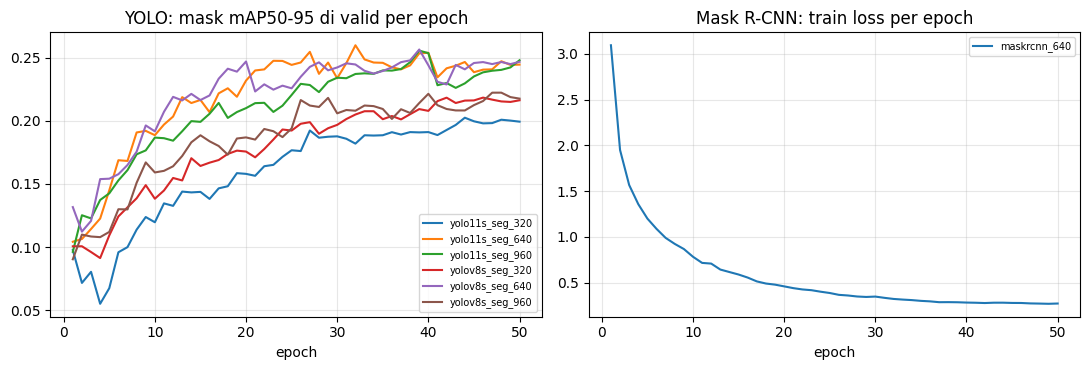

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in sorted(RESULTS):
    p = f"{SAVE_DIR}/{name}/results.csv"
    if not os.path.exists(p): continue
    d = pd.read_csv(p); d.columns = d.columns.str.strip()
    if name.startswith("maskrcnn"):
        ax[1].plot(d["epoch"], d["train_loss"], label=name)
    elif "metrics/mAP50-95(M)" in d.columns:
        ax[0].plot(d["epoch"], d["metrics/mAP50-95(M)"], label=name)
ax[0].set_title("YOLO: mask mAP50-95 di valid per epoch"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].set_title("Mask R-CNN: train loss per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/kurva_training.png", dpi=150, bbox_inches="tight"); plt.show()

## Visualisasi prediksi
Kolom pertama = ground truth (anotasi asli), kolom lain = prediksi tiap model. Warna dan nama kelas sama di semua kolom. Fungsi ini juga dipakai untuk test set buatanmu (untuk analisis kegagalan).

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


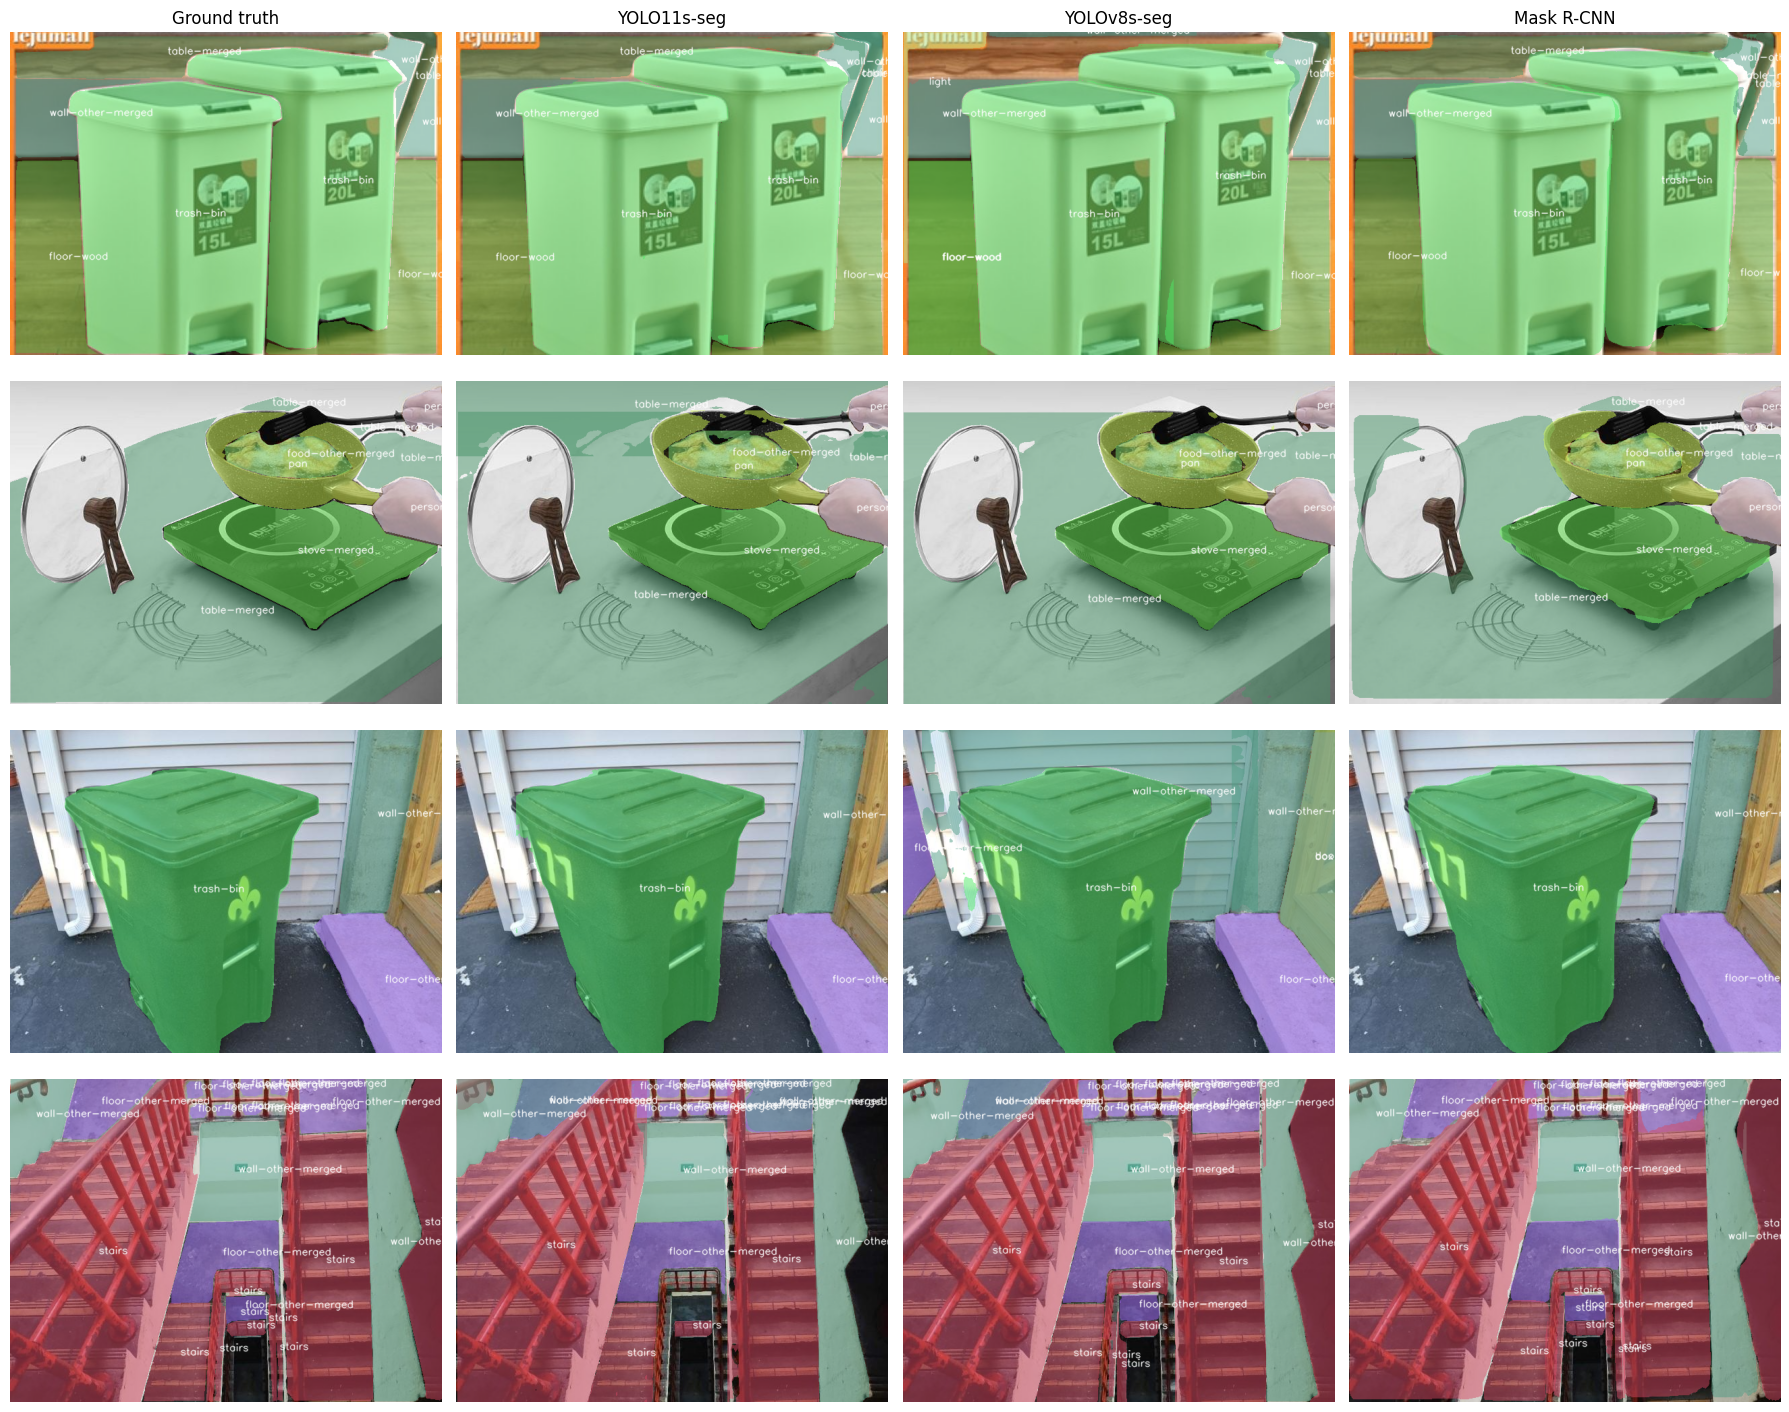

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


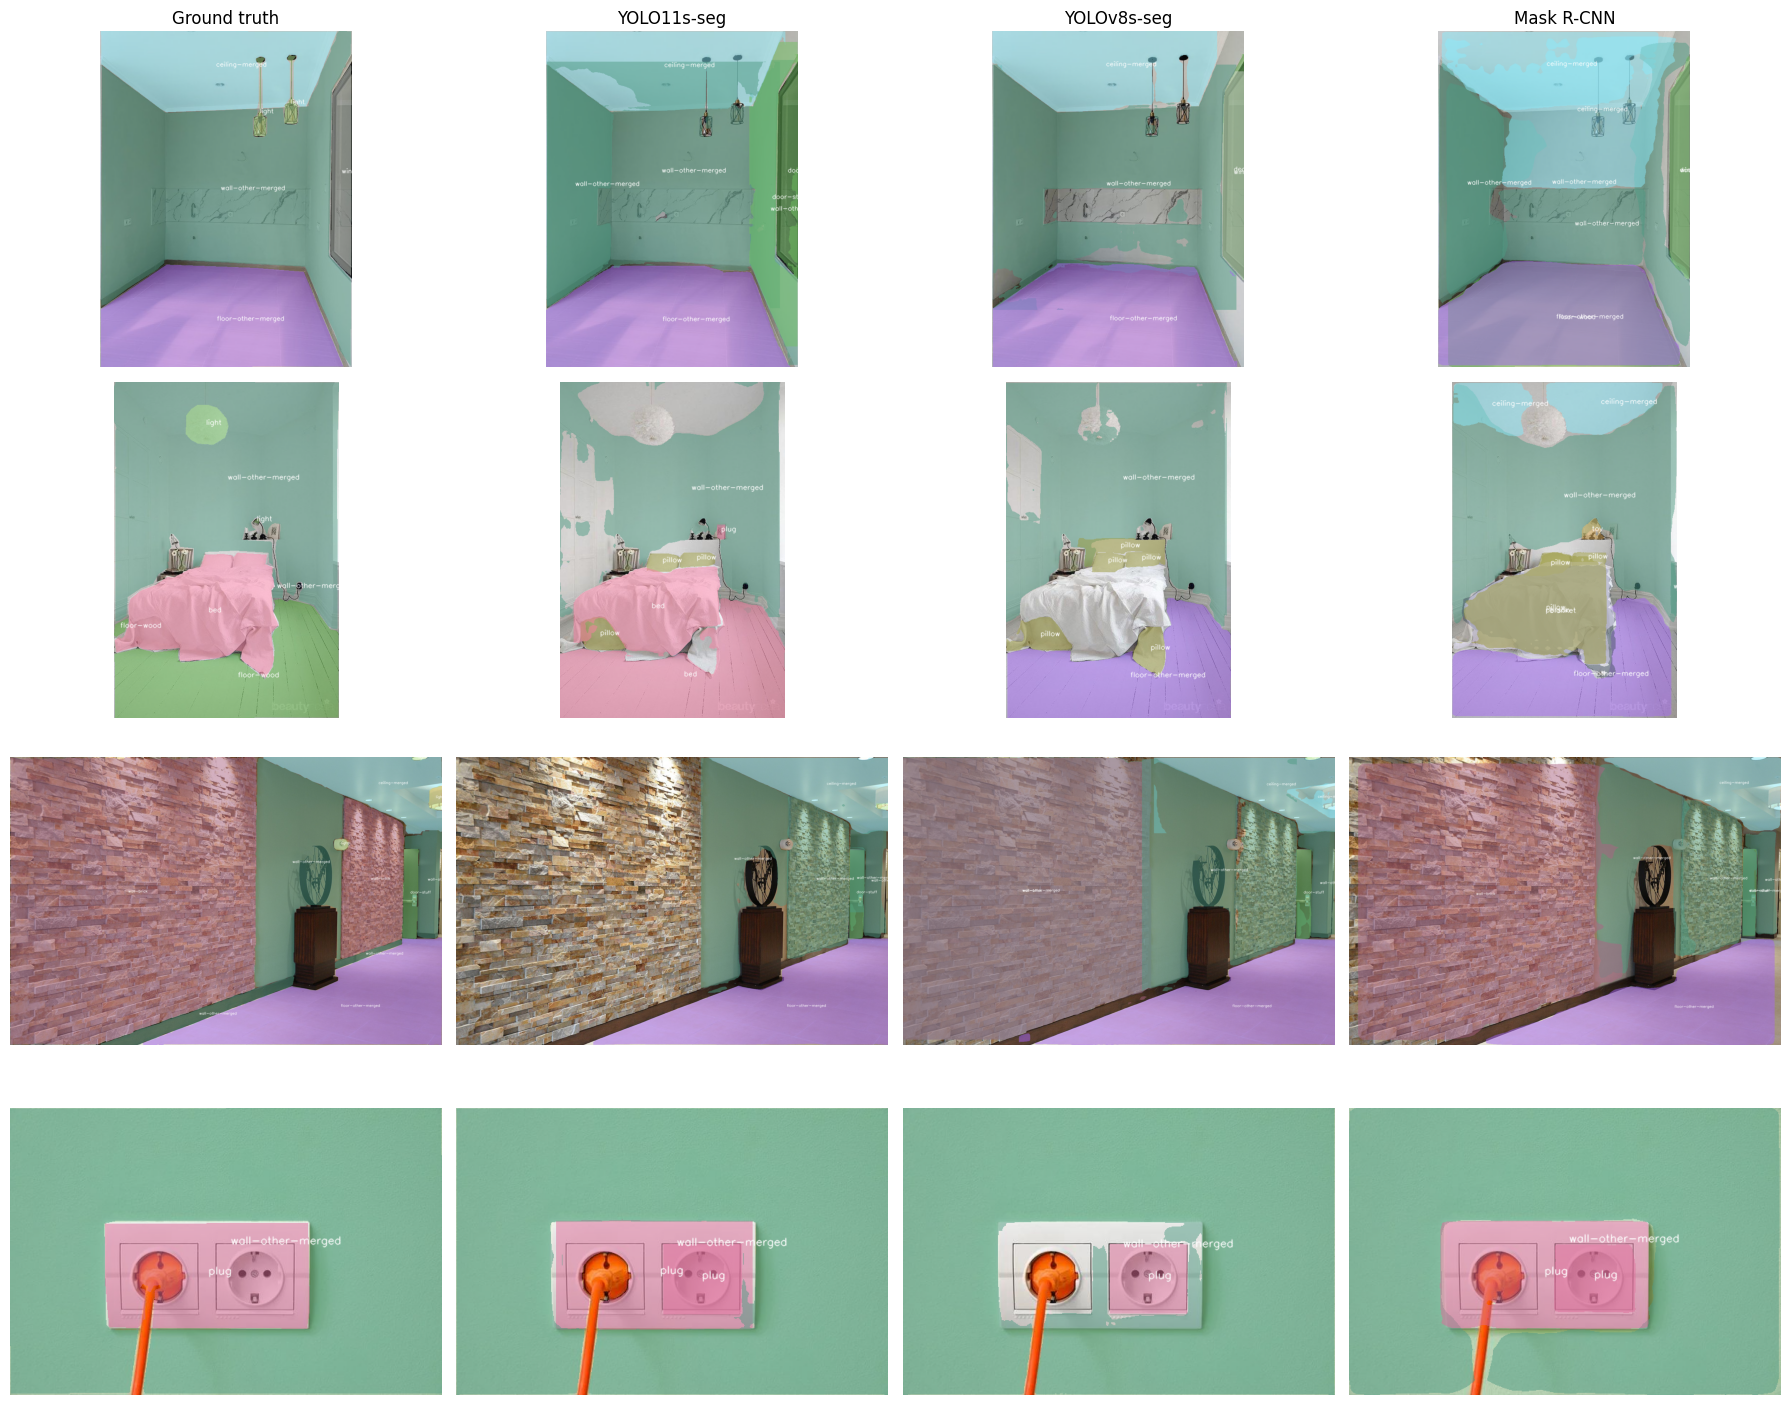

In [17]:
import cv2
import matplotlib.pyplot as plt

PALETTE = np.random.RandomState(0).randint(60, 255, (len(NAMES), 3))   # warna tetap per kelas

def overlay(img, masks, idxs, alpha=0.5):
    out = img.astype(np.float32).copy()
    for m, k in zip(masks, idxs):
        m = m > 0
        if m.any():
            out[m] = (1 - alpha) * out[m] + alpha * PALETTE[k]
    out = out.astype(np.uint8)
    for m, k in zip(masks, idxs):
        ys, xs = np.where(m > 0)
        if len(xs):
            cv2.putText(out, NAMES[k], (int(xs.mean()), int(ys.mean())),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    return out

def visualize(split_dir, tag, n=4, size=BASE_SIZE, seed=SEED, conf=0.25):
    gt = COCO(f"{split_dir}/_annotations.coco.json")
    cid2idx = {c["id"]: name2idx[c["name"]] for c in gt.dataset["categories"] if c["name"] in name2idx}
    yolos = {}
    for t, title in [("yolo11s_seg", "YOLO11s-seg"), ("yolov8s_seg", "YOLOv8s-seg")]:
        p = f"{SAVE_DIR}/{t}_{size}/weights/best.pt"
        if os.path.exists(p): yolos[title] = YOLO(p)
    rcnn = load_maskrcnn(size) if os.path.exists(f"{SAVE_DIR}/maskrcnn_{size}/last.pt") else None
    cols = ["Ground truth"] + list(yolos) + (["Mask R-CNN"] if rcnn else [])
    ids = random.Random(seed).sample(sorted(gt.imgs), min(n, len(gt.imgs)))
    fig, axes = plt.subplots(len(ids), len(cols), figsize=(4.5 * len(cols), 3.6 * len(ids)), squeeze=False)
    for r, iid in enumerate(ids):
        path = f"{split_dir}/{gt.imgs[iid]['file_name']}"
        img = np.array(Image.open(path).convert("RGB"))
        anns = [a for a in gt.loadAnns(gt.getAnnIds(imgIds=iid, iscrowd=False)) if a["category_id"] in cid2idx]
        row = [overlay(img, [gt.annToMask(a) for a in anns], [cid2idx[a["category_id"]] for a in anns])]
        for m in yolos.values():
            res = m.predict(path, imgsz=size, conf=conf, device=0, retina_masks=True, verbose=False)[0]
            if res.masks is None: row.append(img)
            else: row.append(overlay(img, res.masks.data.cpu().numpy(), res.boxes.cls.int().cpu().tolist()))
        if rcnn:
            with torch.no_grad():
                o = rcnn([TF.to_tensor(Image.fromarray(img)).to(dev)])[0]
            keep = o["scores"] > 0.5
            row.append(overlay(img, (o["masks"][keep][:, 0] > 0.5).cpu().numpy(), [int(l) - 1 for l in o["labels"][keep]]))
        for c, im in enumerate(row):
            axes[r][c].imshow(im); axes[r][c].axis("off")
            if r == 0: axes[r][c].set_title(cols[c])
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/visualisasi_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()
    if rcnn: del rcnn; torch.cuda.empty_cache()

visualize(f"{ROOT}/train", "train")
visualize(f"{ROOT}/test", "test")

In [18]:
from collections import Counter

# daftar kelas yang dipakai model (65 kelas)
print(len(NAMES))
for i, n in enumerate(NAMES):
    print(i, n)

# jumlah instance per kelas di train set
cnt = Counter(cats[a["category_id"]] for a in coco["annotations"])
for name, c in cnt.most_common():
    print(f"{c:5d}  {name}")

65
0 backpack
1 bed
2 blanket
3 book
4 bottle
5 bowl
6 box
7 cabinet-merged
8 cardboard
9 ceiling-merged
10 cell phone
11 chair
12 clock
13 couch
14 counter
15 cup
16 curtain
17 dining table
18 door-stuff
19 fire-extinguisher
20 floor-other-merged
21 floor-wood
22 food-other-merged
23 fork
24 handbag
25 knife
26 laptop
27 light
28 microwave
29 mirror-stuff
30 oven
31 pan
32 paper
33 paper-merged
34 person
35 pillow
36 plate
37 plug
38 potted plant
39 refrigerator
40 remote
41 rug-merged
42 shelf
43 sink
44 spoon
45 st-
46 stairs
47 stove-merged
48 table-merged
49 toilet
50 towel
51 toy
52 trash-bin
53 tree-merged
54 tv
55 vase
56 wall
57 wall-brick
58 wall-other-merged
59 wall-stone
60 wall-tile
61 wall-wood
62 wallet
63 window-blind
64 window-other
  756  wall-other-merged
  319  table-merged
  261  floor-other-merged
  225  pan
  217  chair
  217  toy
  197  wallet
  192  person
  175  stairs
  153  trash-bin
  127  food-other-merged
  105  book
  102  counter
   99  floor-wood
   97

In [19]:
print([c["name"] for c in coco["categories"]])

['indoor-objects', 'backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch', 'counter', 'cup', 'curtain', 'dining table', 'door-stuff', 'fire-extinguisher', 'floor-other-merged', 'floor-wood', 'flower', 'food-other-merged', 'fork', 'hair drier', 'handbag', 'keyboard', 'knife', 'laptop', 'light', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'person', 'pillow', 'plate', 'plug', 'potted plant', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stairs', 'stove-merged', 'table-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'trash-bin', 'tree-merged', 'tv', 'vase', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'wallet', 'window-blind', 'window-other']


## Download test-set-rumah-belva dari Roboflow

In [20]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

user_secrets = UserSecretsClient()
roboflow_api_key = user_secrets.get_secret("ROBOFLOW_API_KEY")

rf_own = Roboflow(api_key=roboflow_api_key)
own_proj = rf_own.workspace("hellow-belva-gmail-com").project("test-set-rumah-belva")
dataset = own_proj.version(1).download("coco-segmentation", location="/kaggle/working/own_coco")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/own_coco in coco-segmentation:: 100%|██████████| 44/44 [00:00<00:00, 818.27it/s]


## Gabung semua split jadi satu folder, lalu cek nama kelas

In [21]:
from collections import Counter

OWN_RAW = "/kaggle/working/own_coco"
OWN     = "/kaggle/working/own_test_all"
os.makedirs(OWN, exist_ok=True)

merged = {"images": [], "annotations": [], "categories": None}
img_id = ann_id = 0
for split in ["train", "valid", "test"]:
    jp = f"{OWN_RAW}/{split}/_annotations.coco.json"
    if not os.path.exists(jp): continue
    d = json.load(open(jp))
    if merged["categories"] is None: merged["categories"] = d["categories"]
    old2new = {}
    for im in d["images"]:
        img_id += 1
        new_name = f"{split}_{im['file_name']}"
        shutil.copy(f"{OWN_RAW}/{split}/{im['file_name']}", f"{OWN}/{new_name}")
        old2new[im["id"]] = img_id
        merged["images"].append({**im, "id": img_id, "file_name": new_name})
    for a in d["annotations"]:
        ann_id += 1
        merged["annotations"].append({**a, "id": ann_id, "image_id": old2new[a["image_id"]]})
json.dump(merged, open(f"{OWN}/_annotations.coco.json", "w"))

own_cats = {c["id"]: c["name"] for c in merged["categories"]}
used_own = Counter(own_cats[a["category_id"]] for a in merged["annotations"])
print(len(merged["images"]), "foto,", len(merged["annotations"]), "anotasi")
bad = {n: c for n, c in used_own.items() if n not in name2idx}
print("Kelas di test sendiri yang TIDAK ada di model:", bad or "tidak ada, aman")
print(used_own.most_common())

41 foto, 277 anotasi
Kelas di test sendiri yang TIDAK ada di model: tidak ada, aman
[('chair', 46), ('pillow', 37), ('floor-other-merged', 33), ('wall-other-merged', 30), ('blanket', 18), ('bed', 14), ('curtain', 13), ('counter', 12), ('dining table', 12), ('vase', 7), ('box', 6), ('backpack', 6), ('plug', 5), ('pan', 5), ('couch', 4), ('door-stuff', 4), ('light', 4), ('plate', 3), ('trash-bin', 3), ('laptop', 2), ('stairs', 2), ('cup', 2), ('rug-merged', 2), ('refrigerator', 1), ('bottle', 1), ('potted plant', 1), ('toilet', 1), ('ceiling-merged', 1), ('sink', 1), ('stove-merged', 1)]


## Cek Resize Foto

In [22]:
import cv2

MAXS = 1024   # sisi terpanjang setelah diperkecil
coco = json.load(open(f"{OWN}/_annotations.coco.json"))
imgmap = {im["id"]: im for im in coco["images"]}

for im in coco["images"]:
    p = f"{OWN}/{im['file_name']}"
    img = cv2.imread(p)
    h, w = img.shape[:2]
    s = MAXS / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
        cv2.imwrite(p, img)
    else:
        s = 1.0
    im["_s"] = s
    im["width"], im["height"] = img.shape[1], img.shape[0]

for a in coco["annotations"]:
    s = imgmap[a["image_id"]]["_s"]
    if s != 1.0:
        a["segmentation"] = [[c * s for c in poly] for poly in a["segmentation"]]
        a["bbox"] = [v * s for v in a["bbox"]]
        a["area"] = a["area"] * s * s
for im in coco["images"]:
    im.pop("_s")

json.dump(coco, open(f"{OWN}/_annotations.coco.json", "w"))

sizes = [(im["width"], im["height"]) for im in coco["images"]]
print("ukuran terbesar:", max(max(s) for s in sizes), "| contoh:", sizes[:3])

ukuran terbesar: 1024 | contoh: [(768, 1024), (768, 1024), (768, 1024)]


## Konversi ke format YOLO

In [23]:
coco_to_yolo_seg(OWN, "/kaggle/working/own_yolo/test")
OWN_YAML = "/kaggle/working/own_yolo/data.yaml"
write_yaml(OWN_YAML, "/kaggle/working/own_yolo", only_test=True)

## Evaluasi semua model pake test set rumah belva

In [24]:
import gc
import torch

# Contoh: hapus variabel model/data lama jika ada
for var_name in ["model", "optimizer", "imgs", "out", "preds"]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GiB")
    print(f"Reserved : {torch.cuda.memory_reserved() / 1024**3:.2f} GiB")

Allocated: 0.32 GiB
Reserved : 0.50 GiB


In [30]:
import gc

TARGET_DEV = torch.device("cuda:1" if torch.cuda.device_count() > 1 else "cuda:0")

for name, info in list(RESULTS.items()):
    if "train_min" not in info or "own_map" in info:
        continue
    if info["model"] == "maskrcnn":
        with torch.cuda.device(TARGET_DEV):
            model = load_maskrcnn(info["imgsz"]).to(TARGET_DEV)
            mp, mp50, ms = eval_maskrcnn(model, OWN, batch_size=1)
            del model
            gc.collect()
            torch.cuda.empty_cache()
    else:
        mp, mp50, ms = eval_yolo(name, info["imgsz"], OWN_YAML, split="test", device=TARGET_DEV.index)
    log_result(name, own_map=round(mp, 4), own_map50=round(mp50, 4), own_infer_ms=round(ms, 1))
    print(f"[{name}] test sendiri: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:1 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,091,971 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2729.4±821.1 MB/s, size: 228.2 KB)
val: Scanning /kaggle/working/own_yolo/test/labels... 41 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 893.7it/s 0.0s
val: New cache created: /kaggle/working/own_yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.4it/s 0.9s0.4s
                   all         41        277      0.533       0.32      0.284      0.184      0.669      0.265      0.276      0.178
Speed: 0.3ms preprocess, 6.3ms inference, 0.0ms loss, 2.4ms postprocess per image
[yolo11s_seg_320] test sendiri: mask mAP50-95=0.1777  mAP50=0.2759
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:1 (Tesla T4, 14912MiB)
YOLO11

In [31]:
for name, info in list(RESULTS.items()):
    if "train_min" not in info or "own_map" in info:
        continue
    if info["model"] == "maskrcnn":
        model = load_maskrcnn(info["imgsz"])
        mp, mp50, ms = eval_maskrcnn(model, OWN)
        del model; torch.cuda.empty_cache()
    else:
        mp, mp50, ms = eval_yolo(name, info["imgsz"], OWN_YAML, split="test")
    log_result(name, own_map=round(mp, 4), own_map50=round(mp50, 4), own_infer_ms=round(ms, 1))
    print(f"[{name}] test sendiri: mask mAP50-95={mp:.4f}  mAP50={mp50:.4f}")

## Tabel domain shift dan grafik variabel ukuran input

,run,model,imgsz,train_min,map_train,map_valid,map_test_asli,map_test_sendiri,gap_abs,gap_%
6,maskrcnn_640,maskrcnn,640,38.7,0.6203,0.1878,0.1140,0.1625,-0.0485,-42.5439
0,yolo11s_seg_320,yolo11s_seg,320,6.0,0.4817,0.1989,0.0996,0.1777,-0.0781,-78.4137
1,yolo11s_seg_640,yolo11s_seg,640,9.4,0.6564,0.2572,0.1323,0.1867,-0.0544,-41.1187
2,yolo11s_seg_960,yolo11s_seg,960,18.4,0.7177,0.2556,0.1354,0.1548,-0.0194,-14.3279
3,yolov8s_seg_320,yolov8s_seg,320,5.5,0.5321,0.2172,0.1058,0.1996,-0.0938,-88.6578
4,yolov8s_seg_640,yolov8s_seg,640,9.2,0.7125,0.2544,0.1342,0.2219,-0.0877,-65.3502
5,yolov8s_seg_960,yolov8s_seg,960,17.7,0.7399,0.2219,0.1254,0.1526,-0.0272,-21.6906


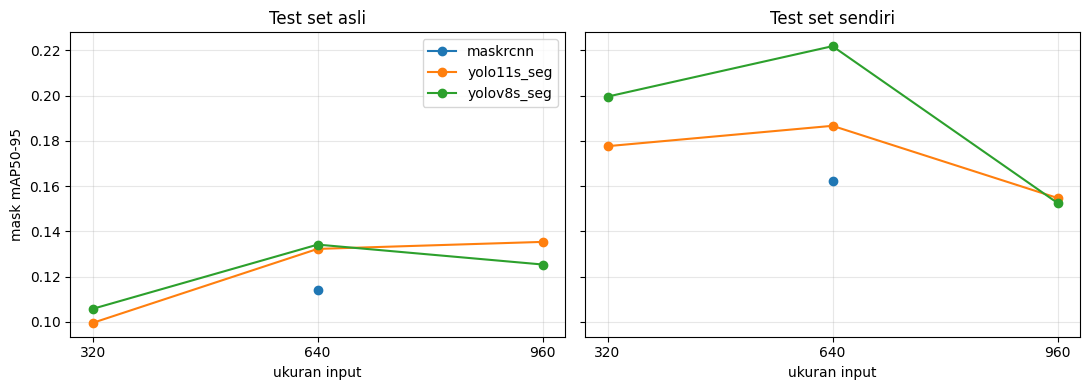

In [32]:
rows = []
for name, i in RESULTS.items():
    if "own_map" not in i: continue
    rows.append(dict(run=name, model=i["model"], imgsz=i["imgsz"], train_min=i.get("train_min"),
                     map_train=i.get("train_map"), map_valid=i.get("valid_map"),
                     map_test_asli=i["test_map"], map_test_sendiri=i["own_map"]))
df = pd.DataFrame(rows)
df["gap_abs"] = df.map_test_asli - df.map_test_sendiri
df["gap_%"]   = 100 * df.gap_abs / df.map_test_asli
df = df.sort_values(["model", "imgsz"]).round(4)
df.to_csv(f"{SAVE_DIR}/tabel_hasil_akhir.csv", index=False)
display(df)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for m, g in df.groupby("model"):
    ax[0].plot(g.imgsz, g.map_test_asli, "o-", label=m)
    ax[1].plot(g.imgsz, g.map_test_sendiri, "o-", label=m)
ax[0].set_title("Test set asli"); ax[1].set_title("Test set sendiri")
for a in ax: a.set_xlabel("ukuran input"); a.set_xticks(SIZES); a.grid(alpha=.3)
ax[0].set_ylabel("mask mAP50-95"); ax[0].legend()
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/grafik_imgsz_domain_shift.png", dpi=150); plt.show()

## Visualisasi prediksi di test set rumah belva

0
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


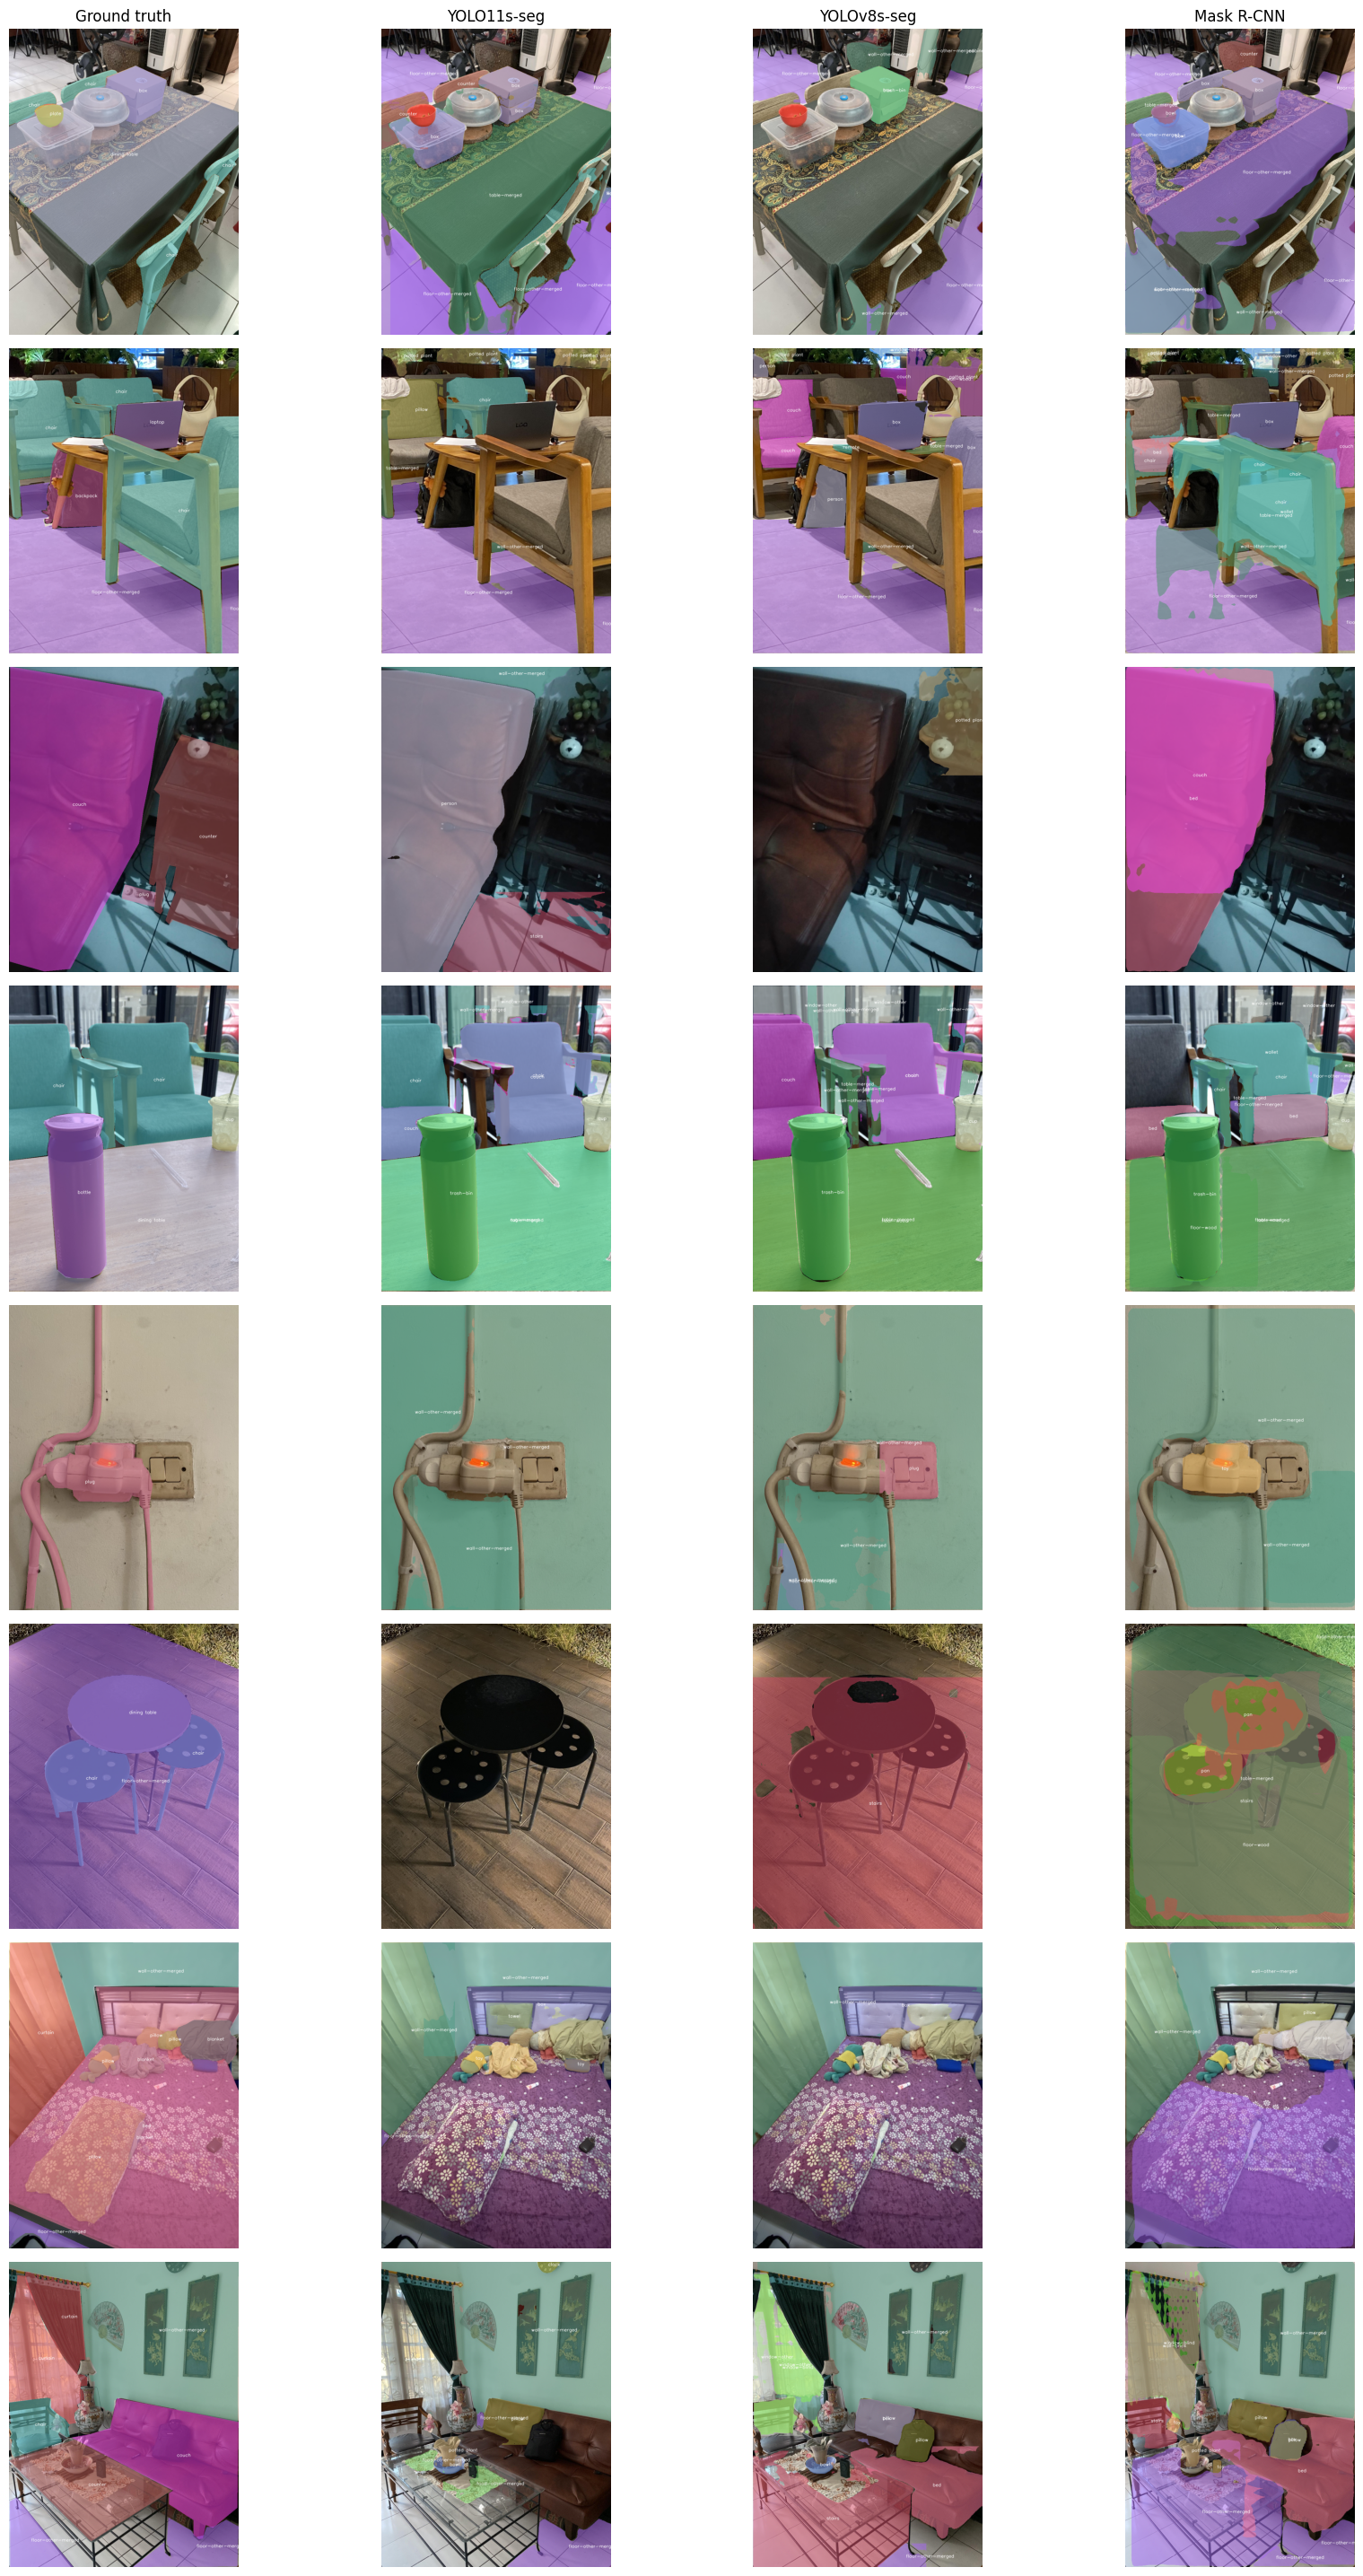

In [34]:
torch.cuda.set_device(0)
torch.cuda.empty_cache()
print(torch.cuda.current_device())
visualize(OWN, "own", n=8)

## Cek foto yang failed

In [35]:
def mask_iou(a, b):
    if a.shape != b.shape:
        b = cv2.resize(b.astype(np.uint8), (a.shape[1], a.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else 0.0

def preds_for(kind, model, path, size, conf=0.25):
    if kind == "yolo":
        r = model.predict(path, imgsz=size, conf=conf, device=0, retina_masks=True, verbose=False)[0]
        if r.masks is None: return [], []
        return list(r.masks.data.cpu().numpy() > 0.5), r.boxes.cls.int().cpu().tolist()
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        o = model([TF.to_tensor(img).to(dev)])[0]
    keep = o["scores"] > conf
    return list((o["masks"][keep][:, 0] > 0.5).cpu().numpy()), [int(l) - 1 for l in o["labels"][keep]]

def per_image_report(kind, model, size, conf=0.25):
    gt = COCO(f"{OWN}/_annotations.coco.json")
    cid2idx = {c["id"]: name2idx[c["name"]] for c in gt.dataset["categories"] if c["name"] in name2idx}
    out = []
    for iid in sorted(gt.imgs):
        fn = gt.imgs[iid]["file_name"]
        anns = [a for a in gt.loadAnns(gt.getAnnIds(imgIds=iid, iscrowd=False)) if a["category_id"] in cid2idx]
        pm, pc = preds_for(kind, model, f"{OWN}/{fn}", size, conf)
        hit = 0
        for a in anns:
            g = gt.annToMask(a).astype(bool); k = cid2idx[a["category_id"]]
            if any(c == k and mask_iou(g, m) >= 0.5 for m, c in zip(pm, pc)): hit += 1
        out.append(dict(image=fn, n_gt=len(anns), n_pred=len(pm), hit=hit, recall=round(hit / max(len(anns), 1), 3)))
    return pd.DataFrame(out).set_index("image")

reps = {}
reps["yolo11s"] = per_image_report("yolo", YOLO(f"{SAVE_DIR}/yolo11s_seg_640/weights/best.pt"), 640)
reps["yolov8s"] = per_image_report("yolo", YOLO(f"{SAVE_DIR}/yolov8s_seg_640/weights/best.pt"), 640)
reps["maskrcnn"] = per_image_report("rcnn", load_maskrcnn(640), 640, conf=0.5)

worst = pd.concat({k: v["recall"] for k, v in reps.items()}, axis=1)
worst["n_gt"] = reps["yolo11s"]["n_gt"]
worst["mean"] = worst[["yolo11s", "yolov8s", "maskrcnn"]].mean(axis=1)
display(worst.sort_values("mean").head(15))

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


,yolo11s,yolov8s,maskrcnn,n_gt,mean
image,,,,,
train_IMG_3876_HEIC.rf.39d6ee2cb6d47588d7c7db2d78c432ba.jpg,0.000,0.000,0.000,1,0.000000
train_IMG_3925_HEIC.rf.d298d35067363a5fe1047e3722bccff8.jpg,0.000,0.000,0.000,4,0.000000
train_IMG_3912_HEIC.rf.ed10ab225c855c44781cff62f34f441e.jpg,0.000,0.000,0.000,3,0.000000
train_IMG_3892_HEIC.rf.a973493665d9475d2a7e7af88676bc3e.jpg,0.091,0.000,0.091,11,0.060667
train_IMG_3885_HEIC.rf.6834e704b0298166abbaf4e0c65cb068.jpg,0.000,0.000,0.250,4,0.083333
train_5ef54706-6e26-41e5-a632-f47321e32773_jpg.rf.2eddc42dbde1678c0bd0ffb62fc3d3a7.jpg,0.000,0.000,0.333,3,0.111000
train_IMG_3904_HEIC.rf.51b7f31125df4f2e88dc718df030a454.jpg,0.273,0.000,0.091,11,0.121333
train_IMG_3910_HEIC.rf.5187e5cca083bae5f3ef25c8cd690d8a.jpg,0.200,0.000,0.200,5,0.133333
train_IMG_3887_HEIC.rf.16e321bcbb3826877beffbd2f47fda4d.jpg,0.200,0.100,0.100,10,0.133333


## Cek kenapa failed

In [36]:
PICK = ["3876", "3925", "3912", "3911", "3885"]
FAIL_IMGS = [n for n in worst.index if any(f"IMG_{p}_HEIC" in n for p in PICK)]
print(len(FAIL_IMGS), FAIL_IMGS)

5 ['train_IMG_3911_HEIC.rf.e1336c18fec4c3872fd6c511e9ef43d7.jpg', 'train_IMG_3925_HEIC.rf.d298d35067363a5fe1047e3722bccff8.jpg', 'train_IMG_3876_HEIC.rf.39d6ee2cb6d47588d7c7db2d78c432ba.jpg', 'train_IMG_3912_HEIC.rf.ed10ab225c855c44781cff62f34f441e.jpg', 'train_IMG_3885_HEIC.rf.6834e704b0298166abbaf4e0c65cb068.jpg']


In [37]:
import re, gc, cv2
torch.cuda.set_device(0)

def mask_iou(a, b):
    if a.shape != b.shape:
        b = cv2.resize(b.astype(np.uint8), (a.shape[1], a.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    u = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / u if u else 0.0

def predict_all(kind, model, path, size, min_conf=0.05):
    """Prediksi sekali pada ambang terendah -> (list mask, list kelas, list skor)."""
    if kind == "yolo":
        r = model.predict(path, imgsz=size, conf=min_conf, device=0, retina_masks=True, verbose=False)[0]
        if r.masks is None: return [], [], []
        return (list(r.masks.data.cpu().numpy() > 0.5),
                r.boxes.cls.int().cpu().tolist(), r.boxes.conf.cpu().tolist())
    img = Image.open(path).convert("RGB")
    with torch.no_grad():
        o = model([TF.to_tensor(img).to(next(model.parameters()).device)])[0]
    keep = o["scores"] > min_conf
    return (list((o["masks"][keep][:, 0] > 0.5).cpu().numpy()),
            [int(l) - 1 for l in o["labels"][keep]], o["scores"][keep].tolist())

GT = COCO(f"{OWN}/_annotations.coco.json")
CID2IDX = {c["id"]: name2idx[c["name"]] for c in GT.dataset["categories"] if c["name"] in name2idx}
FN2ID = {im["file_name"]: iid for iid, im in GT.imgs.items()}

def analyze(kind, model, size, fname, thresholds):
    """Per ambang: (benar, salah_kelas, n_gt, n_pred).
       benar = kelas benar & IoU>=0.5 | salah_kelas = IoU>=0.5 tapi kelas salah."""
    iid = FN2ID[fname]
    anns = [a for a in GT.loadAnns(GT.getAnnIds(imgIds=iid, iscrowd=False)) if a["category_id"] in CID2IDX]
    gts = [(GT.annToMask(a).astype(bool), CID2IDX[a["category_id"]]) for a in anns]
    pm, pc, ps = predict_all(kind, model, f"{OWN}/{fname}", size, min(thresholds))
    out = {}
    for t in thresholds:
        idx = [i for i, s in enumerate(ps) if s >= t]
        hit = wrong = 0
        for g, k in gts:
            ious = [(mask_iou(g, pm[i]), pc[i]) for i in idx]
            if any(iou >= 0.5 and c == k for iou, c in ious): hit += 1
            elif any(iou >= 0.5 for iou, c in ious): wrong += 1
        out[t] = (hit, wrong, len(gts), len(idx))
    return out

def get_model(key, size):
    if key == "maskrcnn":
        p = f"{SAVE_DIR}/maskrcnn_{size}/last.pt"
        return ("rcnn", load_maskrcnn(size)) if os.path.exists(p) else None
    p = f"{SAVE_DIR}/{key}_seg_{size}/weights/best.pt"
    return ("yolo", YOLO(p)) if os.path.exists(p) else None

def short(fn):
    m = re.search(r"IMG_\d+", fn); return m.group(0) if m else fn[:14]

def fmt(h, w, n, p):
    return f"{h}/{n}" + (f" (+{w} salah kelas)" if w else "") + f" | pred={p}"

MODELS = ["yolo11s", "yolov8s", "maskrcnn"]
CONFS  = [0.05, 0.25, 0.5]
rows_size, rows_conf = [], []

for key in MODELS:
    for sz in SIZES:
        gm = get_model(key, sz)
        if gm is None:
            print(f"lewati {key} {sz} (bobot tidak ada)"); continue
        kind, m = gm
        thr = 0.25 if kind == "yolo" else 0.5
        for fn in FAIL_IMGS:
            out = analyze(kind, m, sz, fn, sorted(set(CONFS + [thr])))
            rows_size.append(dict(img=short(fn), model=key, size=sz, cell=fmt(*out[thr])))
            if sz == BASE_SIZE:
                for c in CONFS:
                    rows_conf.append(dict(img=short(fn), model=key, conf=c, cell=fmt(*out[c])))
        del m; gc.collect(); torch.cuda.empty_cache()

print("== Sweep ukuran input (ambang default: YOLO 0.25, Mask R-CNN 0.5) ==")
t_size = pd.DataFrame(rows_size).pivot(index="img", columns=["model", "size"], values="cell")
display(t_size); t_size.to_csv(f"{SAVE_DIR}/sweep_ukuran_input.csv")

print(f"== Sweep confidence (ukuran {BASE_SIZE}) ==")
t_conf = pd.DataFrame(rows_conf).pivot(index="img", columns=["model", "conf"], values="cell")
display(t_conf); t_conf.to_csv(f"{SAVE_DIR}/sweep_confidence.csv")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
lewati maskrcnn 320 (bobot tidak ada)
lewati maskrcnn 960 (bobot tidak ada)
== Sweep ukuran input (ambang default: YOLO 0.25, Mask R-CNN 0.5) ==


model                           yolo11s                                 \
size                                320                            640   
img                                                                      
IMG_3876                   0/1 | pred=4                   0/1 | pred=3   
IMG_3885                   0/4 | pred=5  0/4 (+1 salah kelas) | pred=9   
IMG_3911  1/4 (+1 salah kelas) | pred=5                   0/4 | pred=5   
IMG_3912  0/3 (+2 salah kelas) | pred=2  0/3 (+1 salah kelas) | pred=5   
IMG_3925                   0/4 | pred=0                   0/4 | pred=0   

model                                                          yolov8s  \
size                                960                            320   
img                                                                      
IMG_3876                   0/1 | pred=4                   0/1 | pred=6   
IMG_3885  0/4 (+2 salah kelas) | pred=6                   0/4 | pred=7   
IMG_3911                   0/4 | pred=8  1/4 (+1 salah kelas) | pred=4   
IMG_3912                   0/3 | pred=2  0/3 (+1 salah kelas) | pred=2   
IMG_3925                   0/4 | pred=0  0/4 (+1 salah kelas) | pred=1   

model                                                                    \
size                                 640                            960   
img                                                                       
IMG_3876                    0/1 | pred=5                   0/1 | pred=6   
IMG_3885  0/4 (+3 salah kelas) | pred=10  0/4 (+1 salah kelas) | pred=9   
IMG_3911                    1/4 | pred=5  1/4 (+1 salah kelas) | pred=8   
IMG_3912   0/3 (+1 salah kelas) | pred=4  0/3 (+1 salah kelas) | pred=6   
IMG_3925   0/4 (+1 salah kelas) | pred=1  0/4 (+3 salah kelas) | pred=3   

model                           maskrcnn  
size                                 640  
img                                       
IMG_3876                    0/1 | pred=3  
IMG_3885  1/4 (+1 salah kelas) | pred=11  
IMG_3911  1/4 (+2 salah kelas) | pred=13  
IMG_3912  0/3 (+2 salah kelas) | pred=11  
IMG_3925   0/4 (+3 salah kelas) | pred=6

== Sweep confidence (ukuran 640) ==


model                            yolo11s                                 \
conf                                0.05                           0.25   
img                                                                       
IMG_3876                    0/1 | pred=4                   0/1 | pred=3   
IMG_3885  1/4 (+1 salah kelas) | pred=26  0/4 (+1 salah kelas) | pred=9   
IMG_3911  1/4 (+2 salah kelas) | pred=15                   0/4 | pred=5   
IMG_3912  0/3 (+2 salah kelas) | pred=11  0/3 (+1 salah kelas) | pred=5   
IMG_3925                    1/4 | pred=5                   0/4 | pred=0   

model                                          yolov8s  \
conf              0.50                            0.05   
img                                                      
IMG_3876  0/1 | pred=2                    0/1 | pred=7   
IMG_3885  0/4 | pred=4  0/4 (+3 salah kelas) | pred=25   
IMG_3911  0/4 | pred=0  1/4 (+2 salah kelas) | pred=18   
IMG_3912  0/3 | pred=1  0/3 (+3 salah kelas) | pred=11   
IMG_3925  0/4 | pred=0   0/4 (+1 salah kelas) | pred=5   

model                                                                    \
conf                                0.25                           0.50   
img                                                                       
IMG_3876                    0/1 | pred=5                   0/1 | pred=4   
IMG_3885  0/4 (+3 salah kelas) | pred=10  0/4 (+2 salah kelas) | pred=6   
IMG_3911                    1/4 | pred=5                   1/4 | pred=2   
IMG_3912   0/3 (+1 salah kelas) | pred=4                   0/3 | pred=1   
IMG_3925   0/4 (+1 salah kelas) | pred=1  0/4 (+1 salah kelas) | pred=1   

model                           maskrcnn                                  \
conf                                0.05                            0.25   
img                                                                        
IMG_3876                   0/1 | pred=19                    0/1 | pred=5   
IMG_3885  1/4 (+2 salah kelas) | pred=39  1/4 (+2 salah kelas) | pred=15   
IMG_3911  2/4 (+1 salah kelas) | pred=49  1/4 (+2 salah kelas) | pred=19   
IMG_3912  0/3 (+2 salah kelas) | pred=45  0/3 (+2 salah kelas) | pred=22   
IMG_3925  1/4 (+3 salah kelas) | pred=26  1/4 (+2 salah kelas) | pred=11   

model                                     
conf                                0.50  
img                                       
IMG_3876                    0/1 | pred=3  
IMG_3885  1/4 (+1 salah kelas) | pred=11  
IMG_3911  1/4 (+2 salah kelas) | pred=13  
IMG_3912  0/3 (+2 salah kelas) | pred=11  
IMG_3925   0/4 (+3 salah kelas) | pred=6

In [38]:
import shutil

shutil.make_archive("/kaggle/working/bukti_training_lengkap", "zip", SAVE_DIR)

light = "/kaggle/working/bukti_ringan"
shutil.rmtree(light, ignore_errors=True)
shutil.copytree(SAVE_DIR, light, ignore=shutil.ignore_patterns("*.pt", "*.onnx"))
shutil.make_archive("/kaggle/working/bukti_training_ringan", "zip", light)
shutil.rmtree(light)